<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS07/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

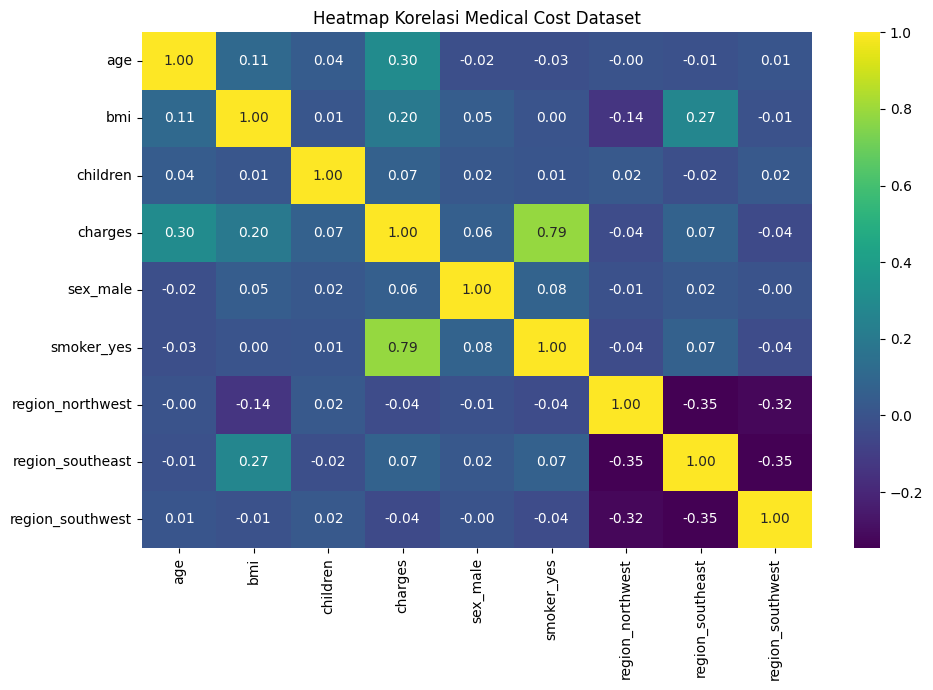

=== Evaluasi Multiple Linear Regression ===
R-squared (R²): 0.7836
MSE           : 33596915.85
MAE           : 4181.19


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Membaca dataset
data = pd.read_csv('insurance.csv')

# 2. Mengubah data kategorikal menjadi numerik untuk heatmap
data_encoded = pd.get_dummies(data, drop_first=True, dtype=int)

# 3. Heatmap korelasi
plt.figure(figsize=(10, 7))
sns.heatmap(
    data_encoded.corr(),
    annot=True,
    cmap='viridis',
    fmt='.2f'
)
plt.title('Heatmap Korelasi Medical Cost Dataset')
plt.tight_layout()
plt.show()

# 4. Menentukan fitur dan target
X = data.drop('charges', axis=1)
y = data['charges']

X = pd.get_dummies(X, drop_first=True, dtype=int)

# 5. Membagi data latih dan data uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 7. Membuat dan melatih model
model = LinearRegression()
model.fit(X_train, y_train)

# 8. Prediksi
y_pred = model.predict(X_test)

# 9. Evaluasi model
print("=== Evaluasi Multiple Linear Regression ===")
print(f"R-squared (R²): {r2_score(y_test, y_pred):.4f}")
print(f"MSE           : {mean_squared_error(y_test, y_pred):.2f}")
print(f"MAE           : {mean_absolute_error(y_test, y_pred):.2f}")


**Variabel:**

- age: Usia individu
- sex: Jenis kelamin
- bmi: Indeks massa tubuh
- children: Jumlah anak yang ditanggung
- smoker: Status merokok
- region: Wilayah tempat tinggal
- charges: Biaya medis personal sebagai target prediksi

Variabel bebas adalah age, sex, bmi, children, smoker, dan region, sedangkan variabel targetnya adalah charges

**Analisis:**

Berdasarkan hasil pengujian, model Multiple Linear Regression memperoleh nilai R-squared sebesar 0,7836, yang menunjukkan bahwa model dapat menjelaskan 78,36% variasi biaya medis dalam data uji. Nilai MAE sebesar 4.181,19 berarti rata-rata selisih absolut antara biaya medis aktual dan hasil prediksi adalah 4.181,19 satuan biaya. Sementara itu, nilai MSE sebesar 3.359.691,85 menunjukkan besarnya kesalahan prediksi dalam satuan kuadrat. Hasil ini menunjukkan model mampu menjelaskan sebagian besar variasi biaya medis, tetapi masih memiliki kesalahan prediksi yang perlu diperhatikan.